#### **IMPORTING PACKAGES**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder


#### **LOADING THE DATA**

In [36]:
df = pd.read_csv('c:/Users/BCSbgayet/Downloads/data_set.csv')
df.head()

,Person_id,Survey_date,Round,Status,Tenure,Geography,Province,Matric,Degree,Diploma,...,Math,Mathlit,Additional_lang,Home_lang,Science,Female,Sa_citizen,Birthyear,Birthmonth,Target
0,Id_eqz61wz7yn,2022-02-23,2,studying,NaN,Rural,Mpumalanga,1.0,0.0,0.0,...,0 - 29 %,NaN,50 - 59 %,NaN,0 - 29 %,1,1,2000,5,0
1,Id_kj5k3g5wud,2023-02-06,4,unemployed,427.0,Suburb,North West,1.0,0.0,0.0,...,30 - 39 %,NaN,40 - 49 %,NaN,30 - 39 %,1,1,1989,4,1
2,Id_9h0isj38y4,2022-08-08,3,other,NaN,Urban,Free State,1.0,0.0,0.0,...,30 - 39 %,NaN,40 - 49 %,NaN,30 - 39 %,0,1,1996,7,1
3,Id_5ch3zwpdef,2022-03-16,2,unemployed,810.0,Urban,Eastern Cape,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,1,2000,1,0
4,Id_g4elxibjej,2023-03-22,4,studying,NaN,Urban,Limpopo,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1,1,1998,12,0


## **Section A:** Exploratory Data Analysis (EDA)

### *1.Data Inspection*

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4020 entries, 0 to 4019
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Person_id        4020 non-null   object 
 1   Survey_date      4020 non-null   object 
 2   Round            4020 non-null   int64  
 3   Status           4020 non-null   object 
 4   Tenure           2626 non-null   float64
 5   Geography        4020 non-null   object 
 6   Province         4020 non-null   object 
 7   Matric           3012 non-null   float64
 8   Degree           2189 non-null   float64
 9   Diploma          2211 non-null   float64
 10  Schoolquintile   2359 non-null   float64
 11  Math             997 non-null    object 
 12  Mathlit          1353 non-null   object 
 13  Additional_lang  2018 non-null   object 
 14  Home_lang        381 non-null    object 
 15  Science          732 non-null    object 
 16  Female           4020 non-null   int64  
 17  Sa_citizen    

In [4]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.isnull().sum()

Person_id             0
Survey_date           0
Round                 0
Status                0
Tenure             1394
Geography             0
Province              0
Matric             1008
Degree             1831
Diploma            1809
Schoolquintile     1661
Math               3023
Mathlit            2667
Additional_lang    2002
Home_lang          3639
Science            3288
Female                0
Sa_citizen            0
Birthyear             0
Birthmonth            0
Target                0
dtype: int64

In [5]:
df.describe()

,Round,Tenure,Matric,Degree,Diploma,Schoolquintile,Female,Sa_citizen,Birthyear,Birthmonth,Target
count,4020.000000,2626.000000,3012.000000,2189.000000,2211.000000,2359.000000,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000
mean,3.129851,582.883092,0.850598,0.078118,0.081411,2.696482,0.564428,0.999502,1997.462935,5.344030,0.271891
std,0.978014,621.220657,0.356544,0.268418,0.273527,1.318409,0.495893,0.022302,4.378334,3.805916,0.444989
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1972.000000,1.000000,0.000000
25%,2.000000,95.000000,1.000000,0.000000,0.000000,2.000000,0.000000,1.000000,1995.000000,1.000000,0.000000
50%,3.000000,395.000000,1.000000,0.000000,0.000000,3.000000,1.000000,1.000000,1999.000000,5.000000,0.000000
75%,4.000000,819.000000,1.000000,0.000000,0.000000,4.000000,1.000000,1.000000,2000.000000,9.000000,1.000000
max,4.000000,3560.000000,1.000000,1.000000,1.000000,5.000000,1.000000,1.000000,2004.000000,12.000000,1.000000


In [6]:
def data_diagnostic(df):
        print("#"*50)
        print(df.info())
        print("#"*50)
        print("The number of total rows  {x: .0f} ".format(x=df.shape[0]))
        print("The number of total variables {x: .0f} ".format(x=df.shape[1]))
        print("The variables names {x:} ".format(x=list(df.columns.values)))

        column_headers =list(df.columns.values)
        qualitative_columns = [col for col in column_headers if df[col].dtype=="object"]
        quantitative_columns = [col for col in column_headers if df[col].dtype in ['int64', 'float64']]

        print("The qualitative variables {x:} ".format(x=qualitative_columns))
        print("The quantitative variables {x:} ".format(x=quantitative_columns))
        print("#"*50)
        print("Total number missing value {x:} ".format(x=df.isnull().sum()))

data_diagnostic(df)

##################################################
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4020 entries, 0 to 4019
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Person_id        4020 non-null   object 
 1   Survey_date      4020 non-null   object 
 2   Round            4020 non-null   int64  
 3   Status           4020 non-null   object 
 4   Tenure           2626 non-null   float64
 5   Geography        4020 non-null   object 
 6   Province         4020 non-null   object 
 7   Matric           3012 non-null   float64
 8   Degree           2189 non-null   float64
 9   Diploma          2211 non-null   float64
 10  Schoolquintile   2359 non-null   float64
 11  Math             997 non-null    object 
 12  Mathlit          1353 non-null   object 
 13  Additional_lang  2018 non-null   object 
 14  Home_lang        381 non-null    object 
 15  Science          732 non-null    object 
 16  Female   

### *2.Univarite Analysis*

##### *Numerical variables*

In [7]:
dtypes = df.dtypes.to_frame().reset_index()
dtypes.columns = ['col', 'dtype']
print('Df dtypes:')
dtypes.groupby('dtype').size()

Df dtypes:


dtype
int64       6
float64     5
object     10
dtype: int64

In [8]:
def numeric_analysis(df):
        
    
        return print(df.describe().T)

numeric_analysis(df)

                 count         mean         std     min     25%     50%  \
Round           4020.0     3.129851    0.978014     1.0     2.0     3.0   
Tenure          2626.0   582.883092  621.220657     0.0    95.0   395.0   
Matric          3012.0     0.850598    0.356544     0.0     1.0     1.0   
Degree          2189.0     0.078118    0.268418     0.0     0.0     0.0   
Diploma         2211.0     0.081411    0.273527     0.0     0.0     0.0   
Schoolquintile  2359.0     2.696482    1.318409     0.0     2.0     3.0   
Female          4020.0     0.564428    0.495893     0.0     0.0     1.0   
Sa_citizen      4020.0     0.999502    0.022302     0.0     1.0     1.0   
Birthyear       4020.0  1997.462935    4.378334  1972.0  1995.0  1999.0   
Birthmonth      4020.0     5.344030    3.805916     1.0     1.0     5.0   
Target          4020.0     0.271891    0.444989     0.0     0.0     0.0   

                   75%     max  
Round              4.0     4.0  
Tenure           819.0  3560.0  


### Numerical variables visualisation

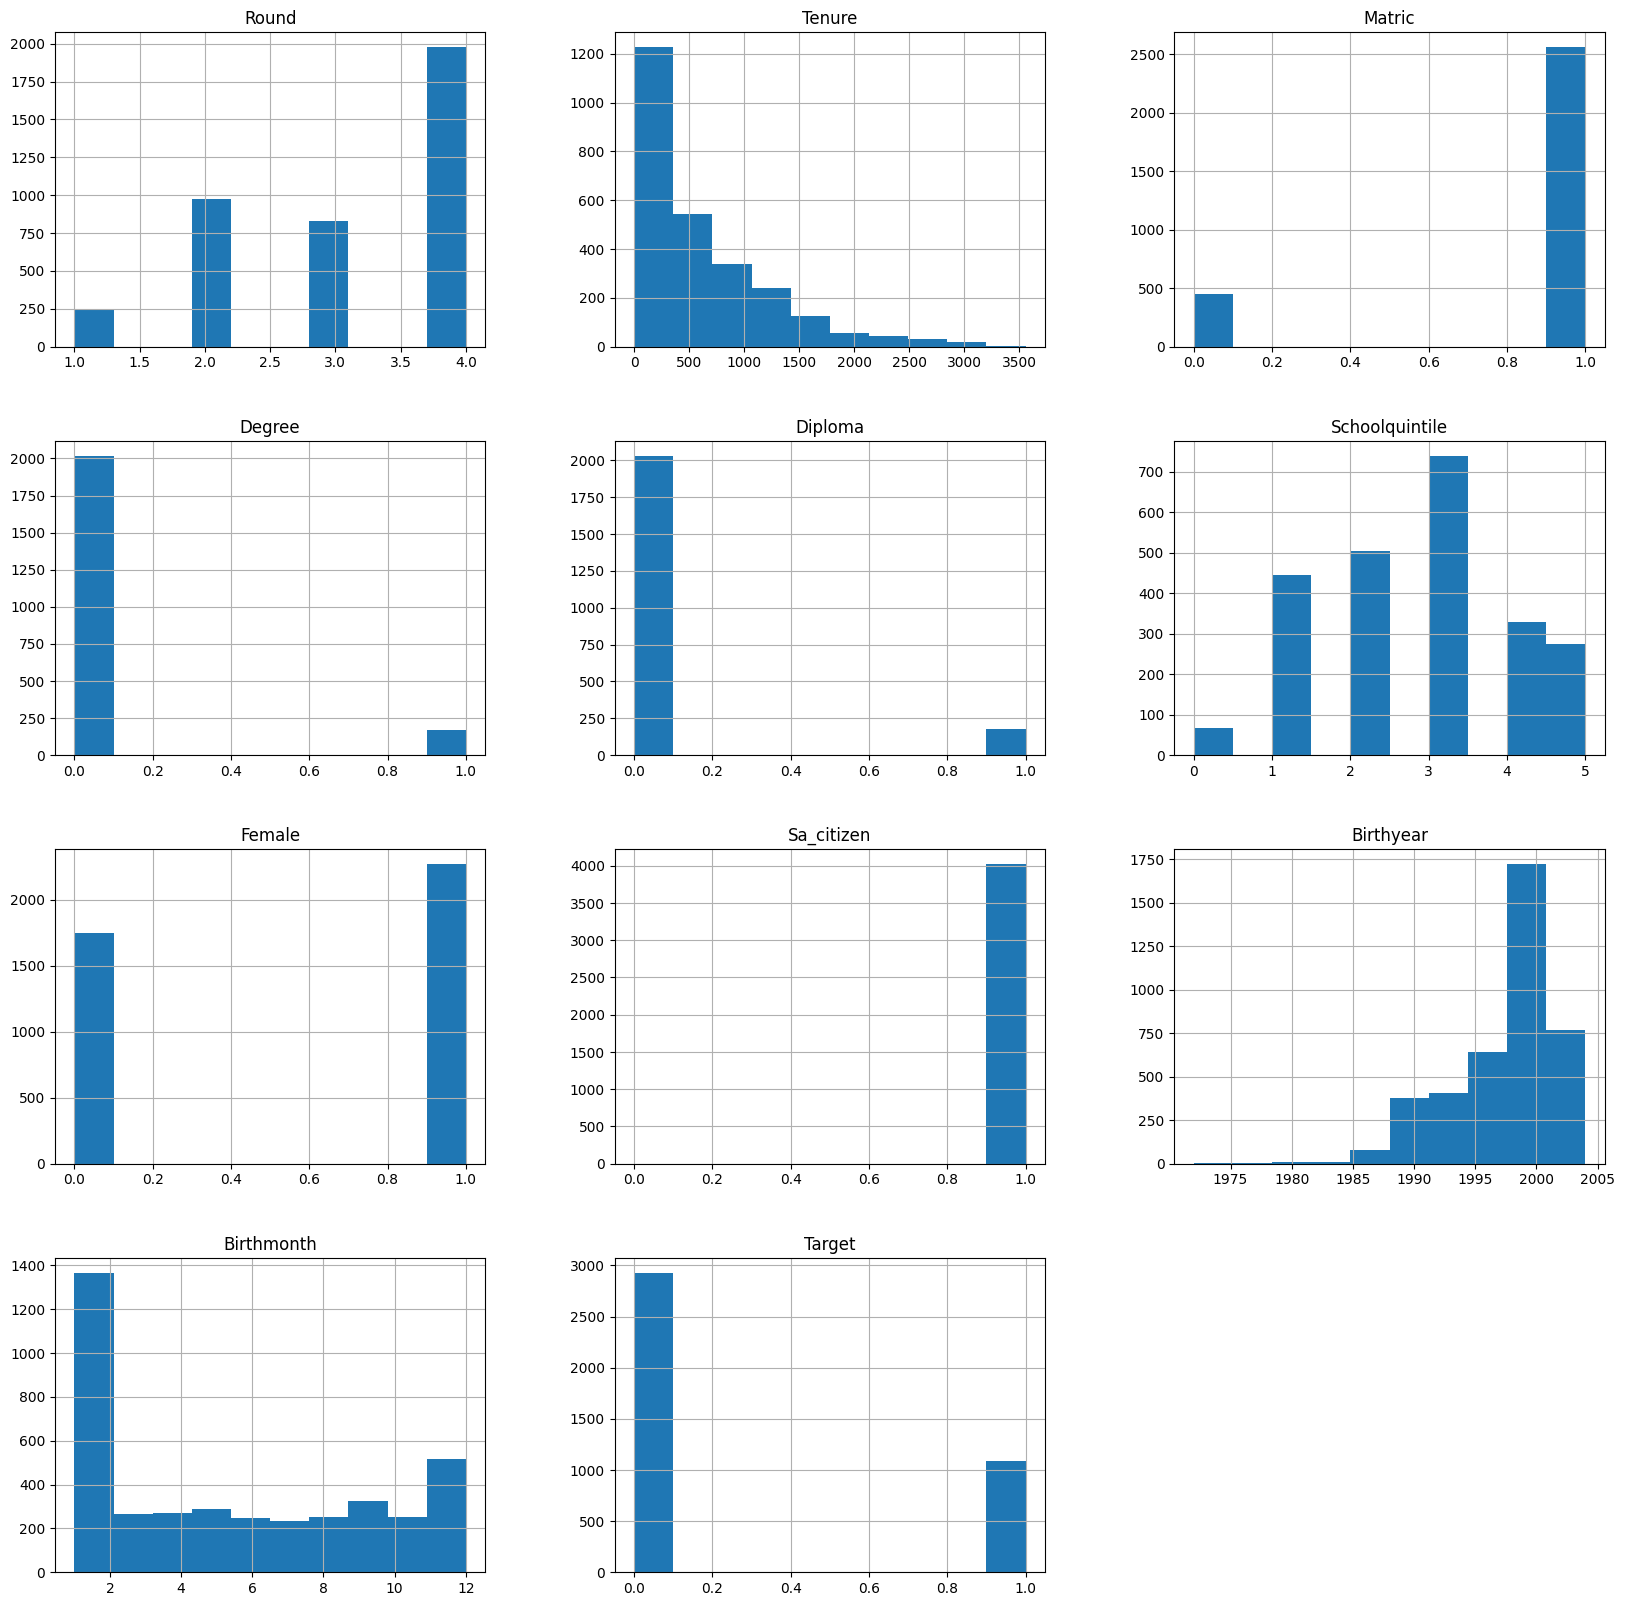

In [9]:
df.hist(bins=10,figsize=(20,20))
plt.show()

### Categorical variables visualisation

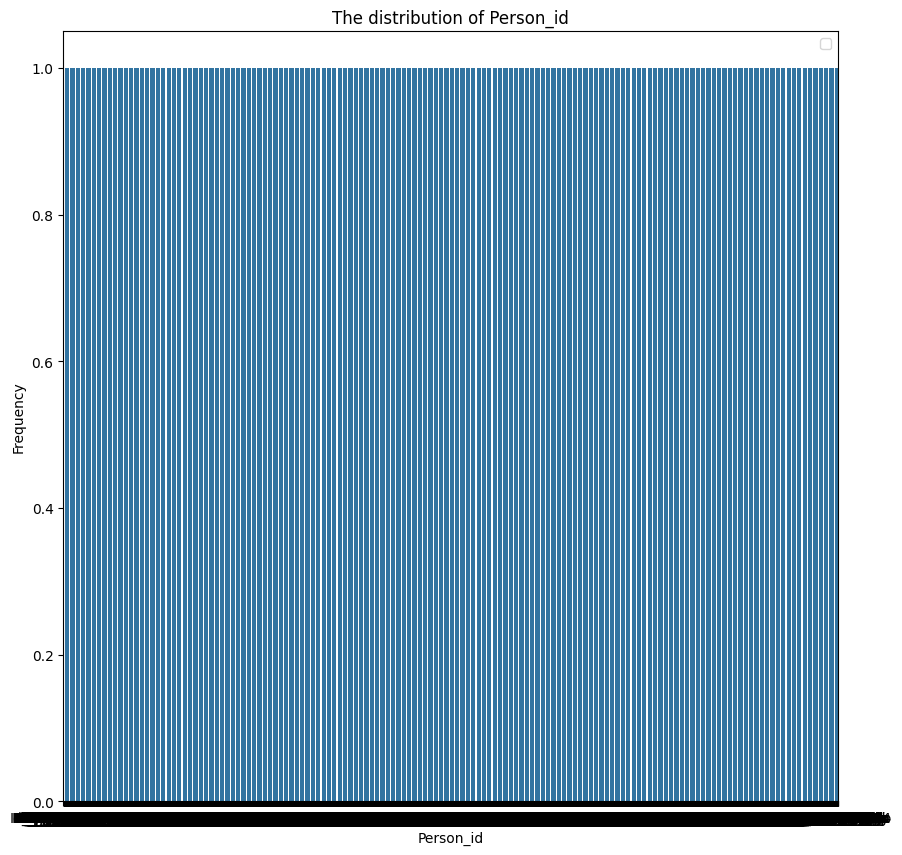

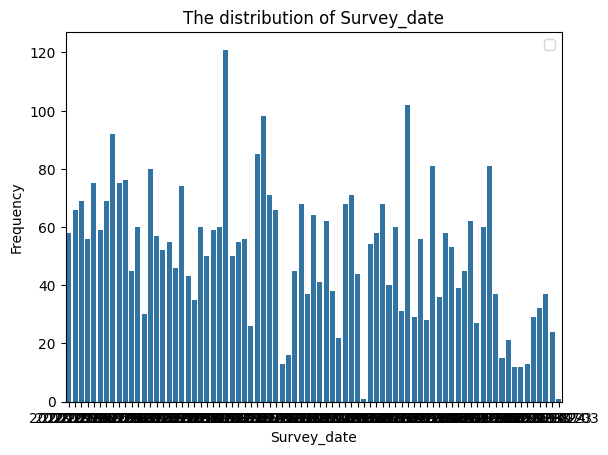

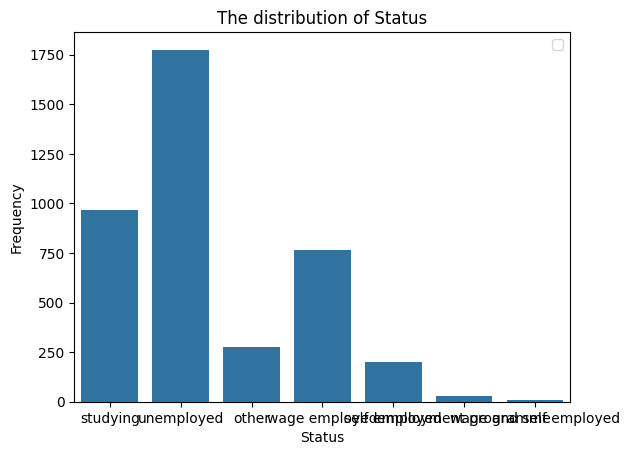

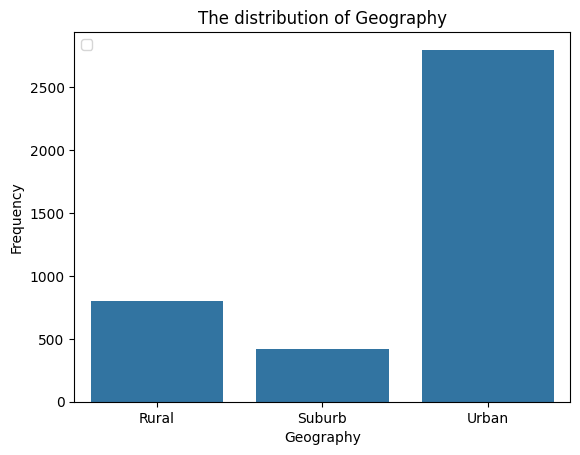

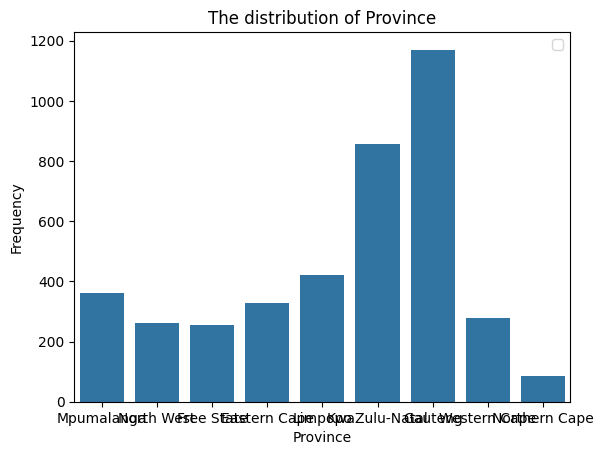

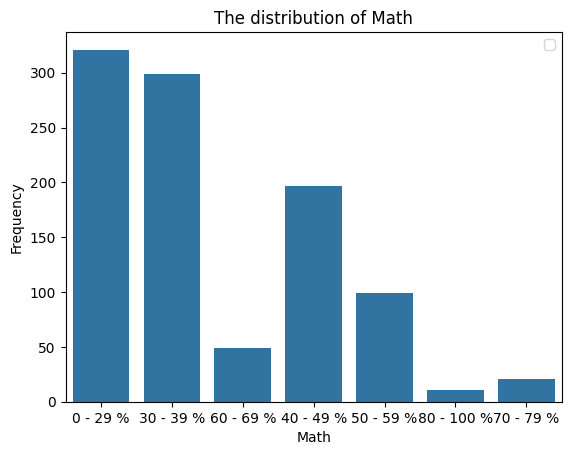

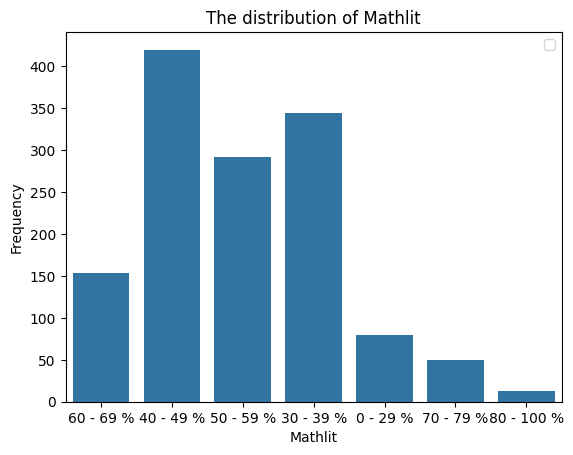

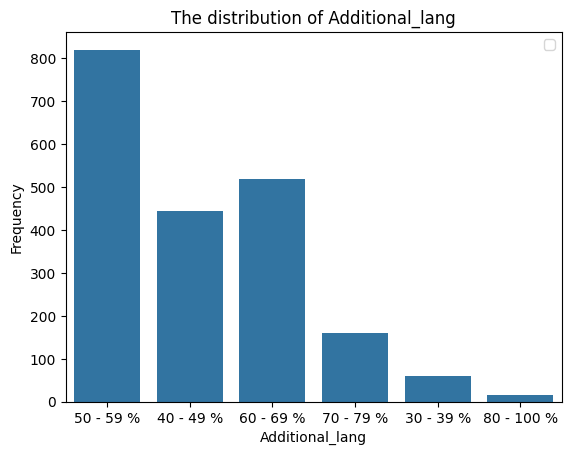

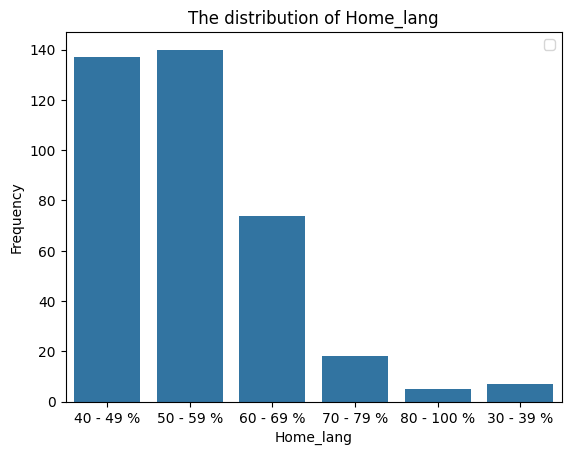

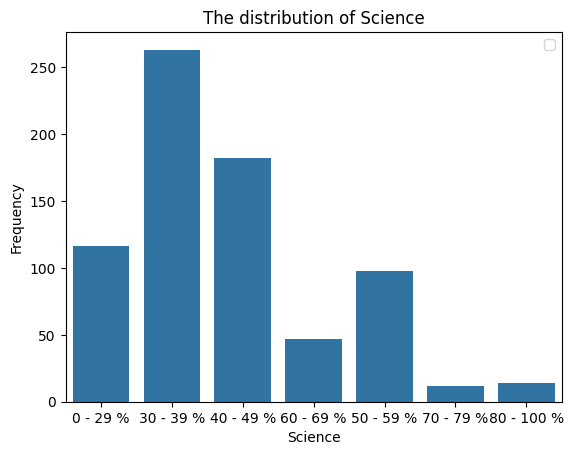

In [11]:
categorical_col = df.select_dtypes(include='object').columns 

plt.figure(figsize=(10,10))
for col in categorical_col:
    sns.countplot(x=col,data=df)
    plt.ylabel('Frequency')
    plt.title(f'The distribution of {col}')
    plt.legend()
    plt.show()

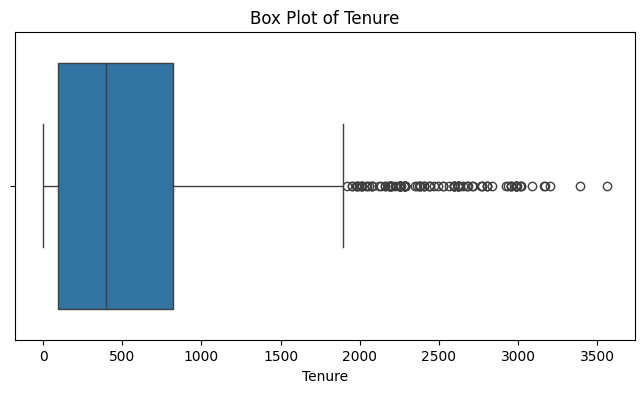

In [46]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Tenure'])
plt.title('Box Plot of Tenure')
plt.show()

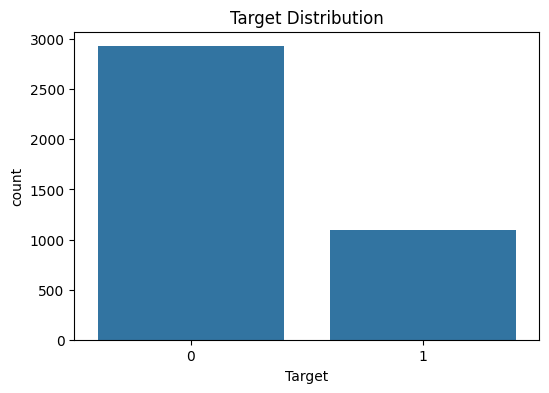

In [47]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Target', data=df)
plt.title('Target Distribution')
plt.show()

### *3.Bivariate Analysis*

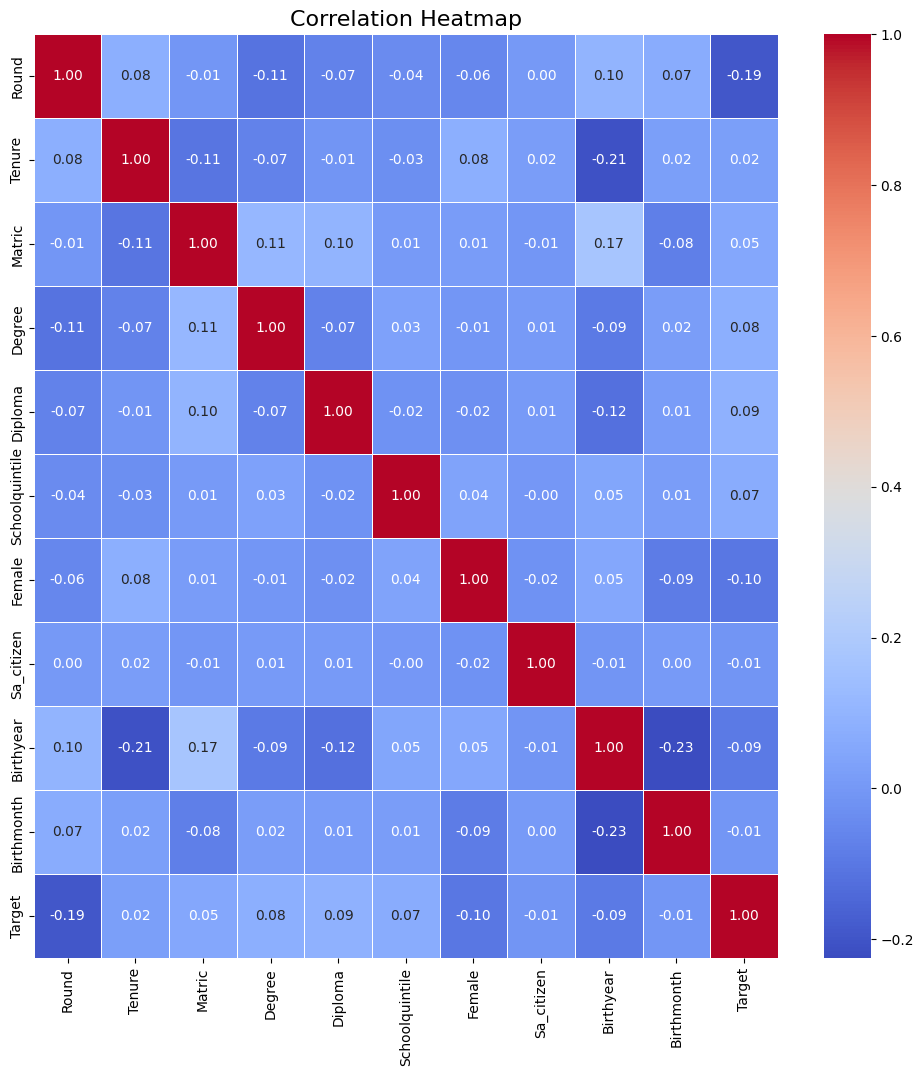

In [45]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

#### Numeric variables vs Target


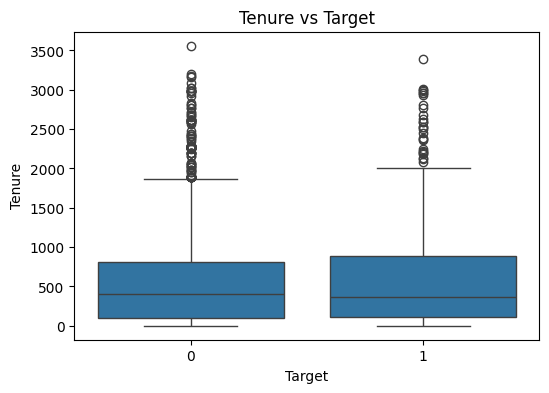

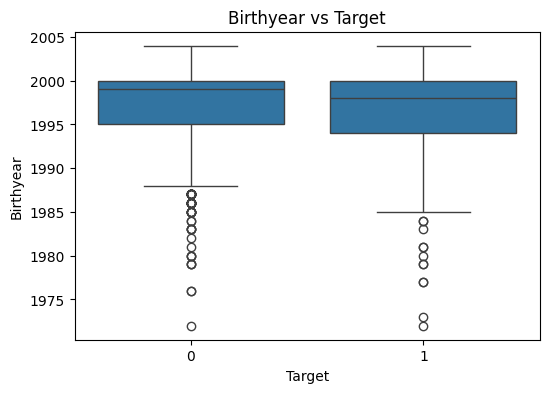

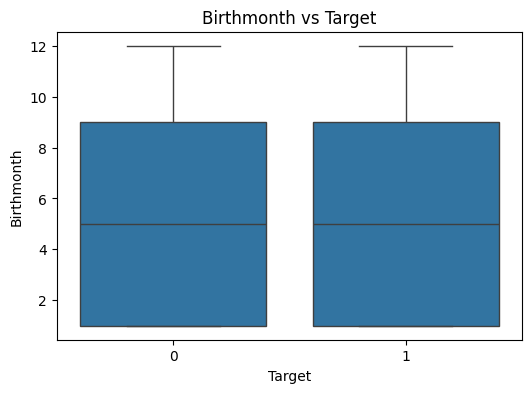

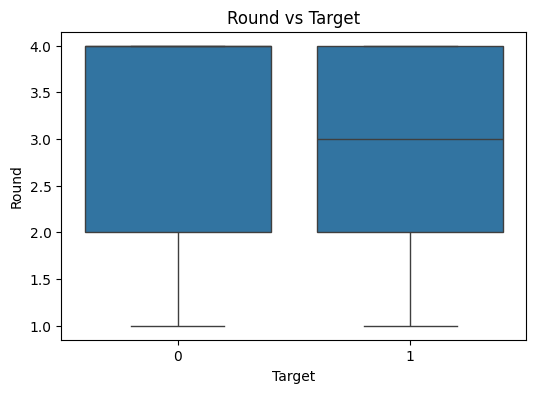

In [14]:
numeric_cols = ['Tenure', 'Birthyear', 'Birthmonth', 'Round']
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Target', y=col, data=df)
    plt.title(f'{col} vs Target')
    plt.show()

#### Categorical variables vs Target


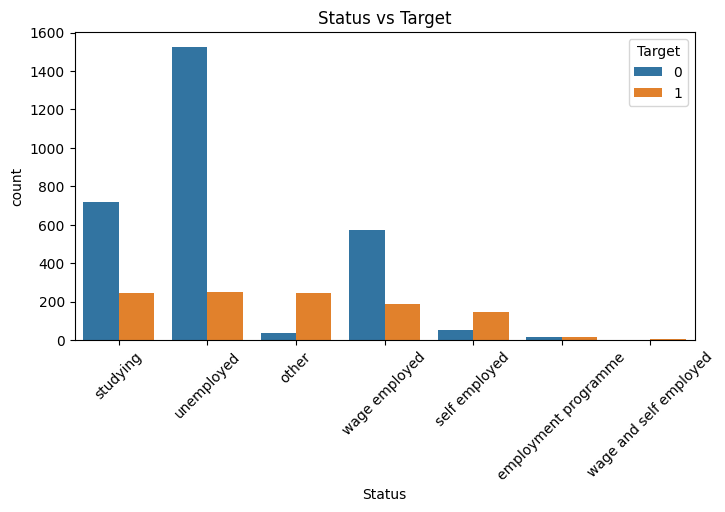

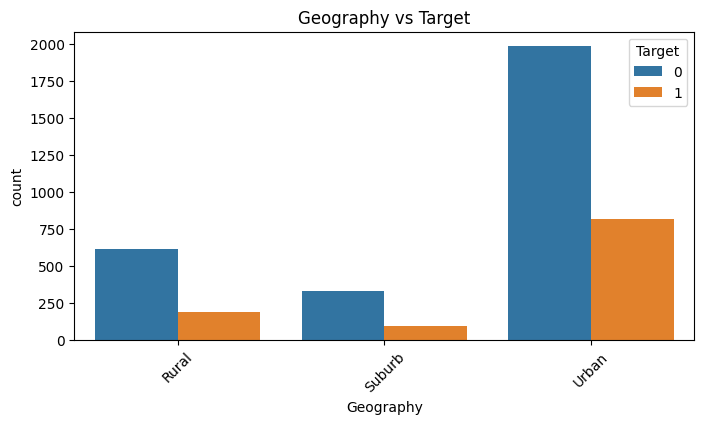

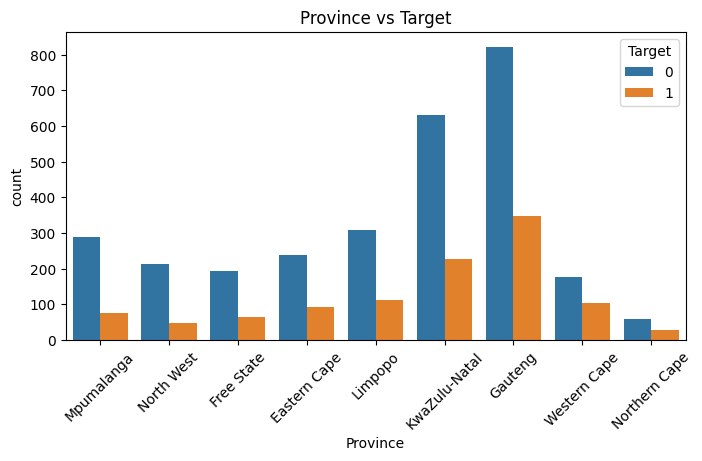

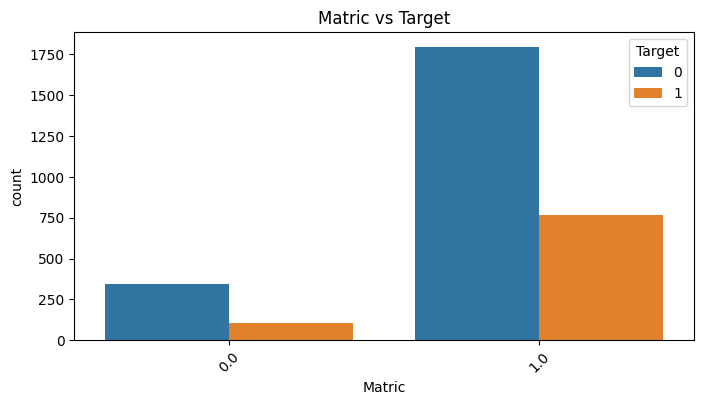

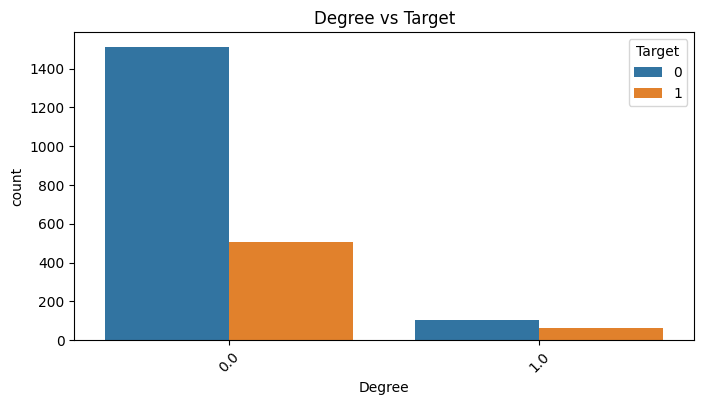

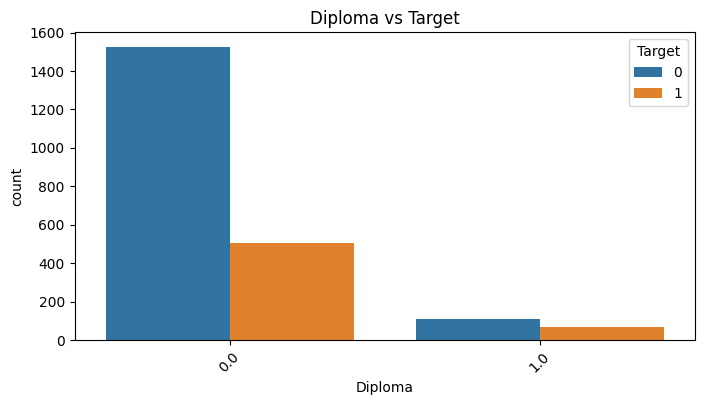

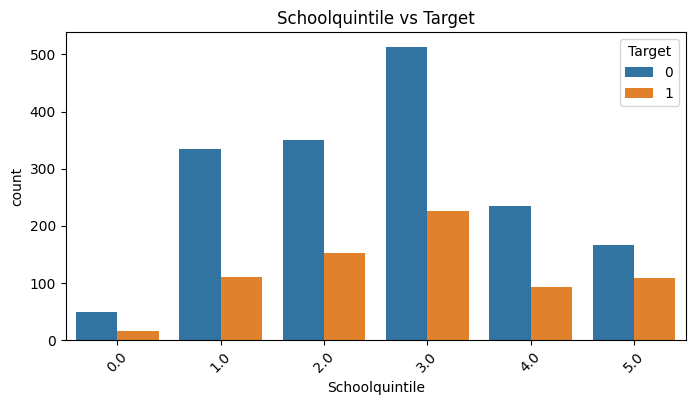

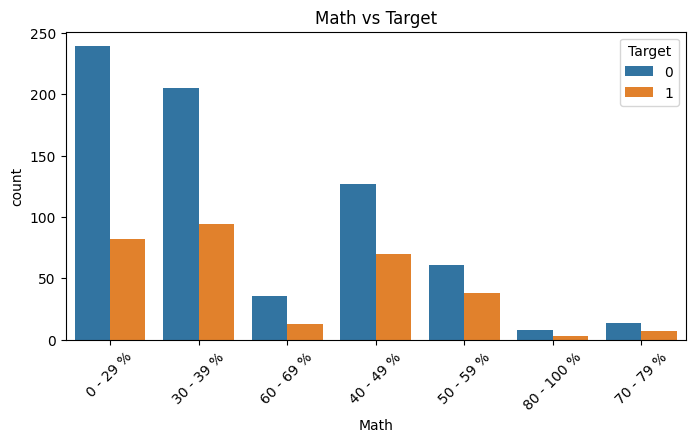

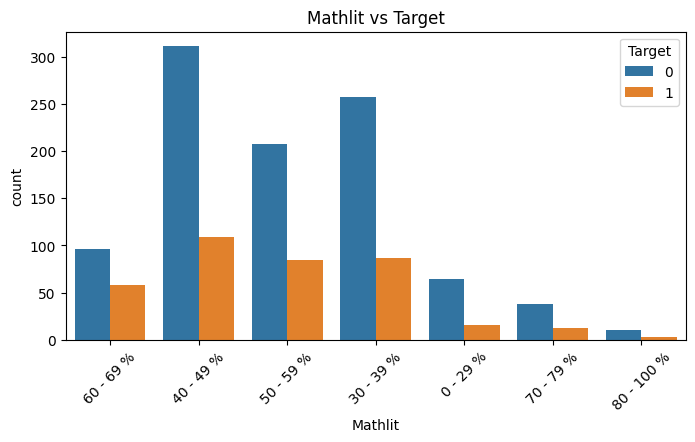

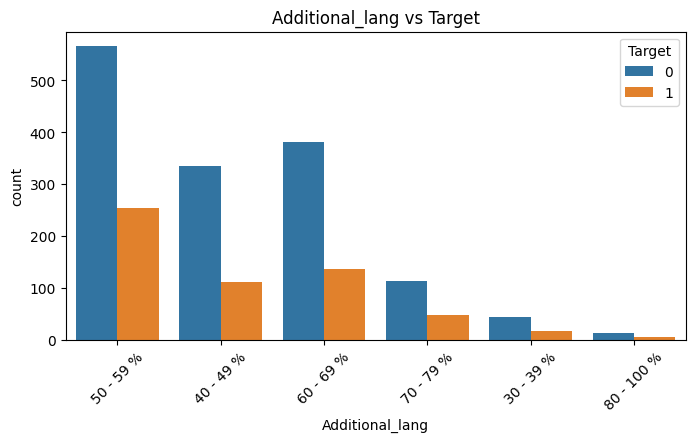

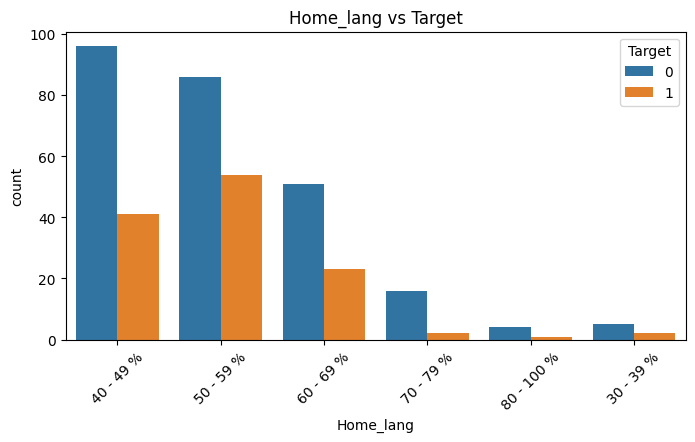

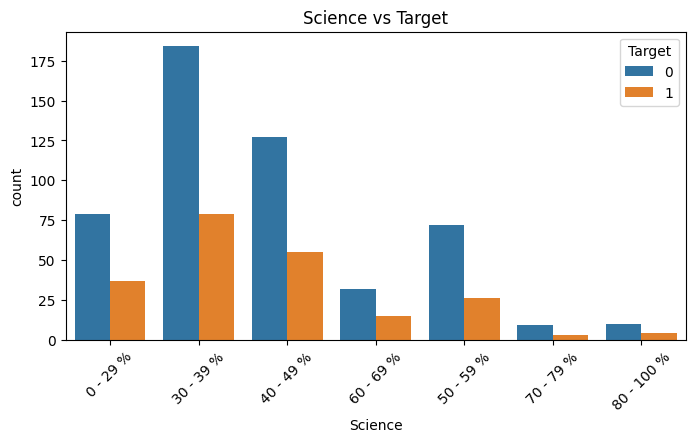

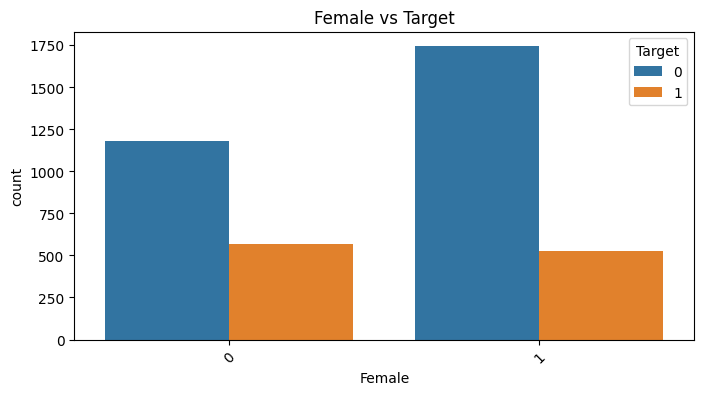

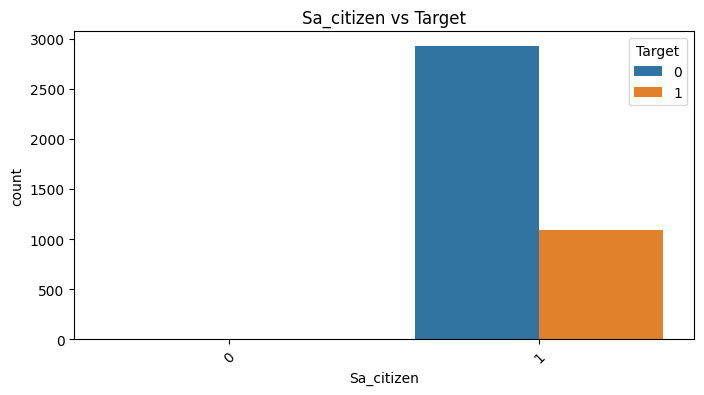

In [15]:
categorical_cols = ['Status', 'Geography', 'Province', 'Matric', 'Degree', 
                    'Diploma', 'Schoolquintile', 'Math', 'Mathlit', 
                    'Additional_lang', 'Home_lang', 'Science', 'Female', 
                    'Sa_citizen']
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, hue='Target', data=df)
    plt.title(f'{col} vs Target')
    plt.xticks(rotation=45)
    plt.show()

### *3.Data Cleaning*

In [37]:
df.drop(['Home_lang', 'Science', 'Math'],axis=1, inplace=True)

In [17]:
df.head()

,Person_id,Survey_date,Round,Status,Tenure,Geography,Province,Matric,Degree,Diploma,...,Math,Mathlit,Additional_lang,Home_lang,Science,Female,Sa_citizen,Birthyear,Birthmonth,Target
0,Id_eqz61wz7yn,2022-02-23,2,studying,NaN,Rural,Mpumalanga,1.0,0.0,0.0,...,14.5,NaN,54.5,NaN,14.5,1,1,2000,5,0
1,Id_kj5k3g5wud,2023-02-06,4,unemployed,427.0,Suburb,North West,1.0,0.0,0.0,...,34.5,NaN,44.5,NaN,34.5,1,1,1989,4,1
2,Id_9h0isj38y4,2022-08-08,3,other,NaN,Urban,Free State,1.0,0.0,0.0,...,34.5,NaN,44.5,NaN,34.5,0,1,1996,7,1
3,Id_5ch3zwpdef,2022-03-16,2,unemployed,810.0,Urban,Eastern Cape,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,1,2000,1,0
4,Id_g4elxibjej,2023-03-22,4,studying,NaN,Urban,Limpopo,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1,1,1998,12,0


In [38]:
def convert_score(score_str):
    if pd.isnull(score_str):
        return np.nan  # on garde les NaN pour imputation après
    else:
        parts = score_str.replace('%', '').split(' - ')
        return (int(parts[0]) + int(parts[1])) / 2

score_cols = ['Mathlit', 'Additional_lang']

for col in score_cols:
    df[col] = df[col].apply(convert_score)

# Handle missing values
df['Tenure'].fillna(df['Tenure'].median(), inplace=True)
df['Mathlit'].fillna(df['Mathlit'].median(), inplace=True)
df['Additional_lang'].fillna(df['Additional_lang'].median(), inplace=True)
df['Matric'].fillna(1, inplace=True)  
df['Degree'].fillna(0, inplace=True) 
df['Diploma'].fillna(0, inplace=True) 
df['Schoolquintile'].fillna(df['Schoolquintile'].mode()[0], inplace=True)


C:\Users\BCSbgayet\AppData\Local\Temp\ipykernel_11916\1480285501.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Tenure'].fillna(df['Tenure'].median(), inplace=True)
C:\Users\BCSbgayet\AppData\Local\Temp\ipykernel_11916\1480285501.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves a

In [27]:
df.isnull().sum()

Person_id          0
Survey_date        0
Round              0
Status             0
Tenure             0
Geography          0
Province           0
Matric             0
Degree             0
Diploma            0
Schoolquintile     0
Mathlit            0
Additional_lang    0
Female             0
Sa_citizen         0
Birthyear          0
Birthmonth         0
Target             0
dtype: int64

In [28]:
df.head()

,Person_id,Survey_date,Round,Status,Tenure,Geography,Province,Matric,Degree,Diploma,Schoolquintile,Mathlit,Additional_lang,Female,Sa_citizen,Birthyear,Birthmonth,Target
0,Id_eqz61wz7yn,2022-02-23,2,studying,395.0,Rural,Mpumalanga,1.0,0.0,0.0,3.0,44.5,54.5,1,1,2000,5,0
1,Id_kj5k3g5wud,2023-02-06,4,unemployed,427.0,Suburb,North West,1.0,0.0,0.0,1.0,44.5,44.5,1,1,1989,4,1
2,Id_9h0isj38y4,2022-08-08,3,other,395.0,Urban,Free State,1.0,0.0,0.0,3.0,44.5,44.5,0,1,1996,7,1
3,Id_5ch3zwpdef,2022-03-16,2,unemployed,810.0,Urban,Eastern Cape,1.0,0.0,0.0,3.0,44.5,54.5,0,1,2000,1,0
4,Id_g4elxibjej,2023-03-22,4,studying,395.0,Urban,Limpopo,1.0,0.0,0.0,3.0,44.5,54.5,1,1,1998,12,0


In [39]:
# Fixing outliers
df.loc[df['Tenure'] > 120, 'Tenure'] = 120
df.loc[df['Birthyear'] < 1987, 'Birthyear'] = 1987

In [40]:
# Fix Schoolquintile (0 is invalid)
df.loc[df['Schoolquintile'] == 0, 'Schoolquintile'] = 1

## **Section B:** Feature Engineering 

In [41]:
df['Sa_citizen'].value_counts()


Sa_citizen
1    4018
0       2
Name: count, dtype: int64

In [42]:
df=df.drop(columns='Person_id')
df=df.drop(columns='Sa_citizen')
df=df.drop(columns='Birthmonth')


##### The variable Sa_citizen was dropped because it is highly imbalanced. Out of 4020 individuals, 4018 are South African citizens and only 2 are not. This lack of variability means that the feature provides no meaningful information to the model, and is therefore not useful for prediction.

In [43]:
# Create Age feature
df['Survey_year'] = pd.to_datetime(df['Survey_date']).dt.year
df['Age'] = df['Survey_year'] - df['Birthyear']
df.drop(['Survey_date', 'Survey_year', 'Birthyear'], axis=1, inplace=True)


In [44]:
# Encode categorical variables
df = pd.get_dummies(df, columns=['Status', 'Geography', 'Province'], drop_first=True)


In [45]:
df.head()

,Round,Tenure,Matric,Degree,Diploma,Schoolquintile,Mathlit,Additional_lang,Female,Target,...,Geography_Suburb,Geography_Urban,Province_Free State,Province_Gauteng,Province_KwaZulu-Natal,Province_Limpopo,Province_Mpumalanga,Province_North West,Province_Northern Cape,Province_Western Cape
0,2,120.0,1.0,0.0,0.0,3.0,44.5,54.5,1,0,...,False,False,False,False,False,False,True,False,False,False
1,4,120.0,1.0,0.0,0.0,1.0,44.5,44.5,1,1,...,True,False,False,False,False,False,False,True,False,False
2,3,120.0,1.0,0.0,0.0,3.0,44.5,44.5,0,1,...,False,True,True,False,False,False,False,False,False,False
3,2,120.0,1.0,0.0,0.0,3.0,44.5,54.5,0,0,...,False,True,False,False,False,False,False,False,False,False
4,4,120.0,1.0,0.0,0.0,3.0,44.5,54.5,1,0,...,False,True,False,False,False,True,False,False,False,False


In [46]:
df.columns

Index(['Round', 'Tenure', 'Matric', 'Degree', 'Diploma', 'Schoolquintile',
       'Mathlit', 'Additional_lang', 'Female', 'Target', 'Age', 'Status_other',
       'Status_self employed', 'Status_studying', 'Status_unemployed',
       'Status_wage and self employed', 'Status_wage employed',
       'Geography_Suburb', 'Geography_Urban', 'Province_Free State',
       'Province_Gauteng', 'Province_KwaZulu-Natal', 'Province_Limpopo',
       'Province_Mpumalanga', 'Province_North West', 'Province_Northern Cape',
       'Province_Western Cape'],
      dtype='object')

## **Section C:** Machine Learning Modeling

In [47]:
# Features and Target
X = df.drop('Target', axis=1)
y = df['Target']

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Suggestion 1 for SMOTE

In [49]:
from imblearn.over_sampling import SMOTE
# Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_smote_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled_smote = scaler.transform(X_test)

### Classification Algorithms

#### **1.Logistic Regression**

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score


log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_smote, y_train_smote)
y_pred_lr = log_reg.predict(X_test_scaled_smote)

print("Classification Report (logistic regression):\n", classification_report(y_test, y_pred_lr))
print("\n F1:", f1_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Classification Report (logistic regression):
               precision    recall  f1-score   support

           0       0.79      0.97      0.87       587
           1       0.81      0.30      0.44       217

    accuracy                           0.79       804
   macro avg       0.80      0.64      0.66       804
weighted avg       0.80      0.79      0.76       804


 F1: 0.4377104377104377
Precision: 0.8125
Recall: 0.2995391705069124
Accuracy: 0.7922885572139303


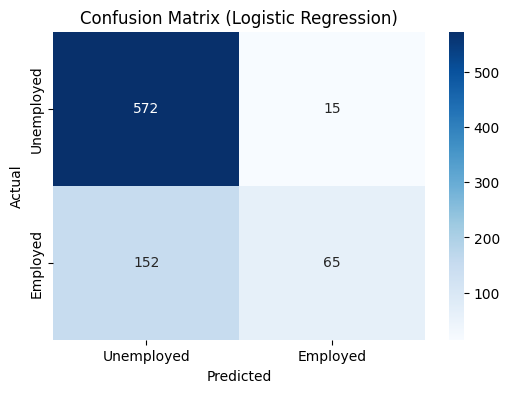

In [52]:
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Unemployed', 'Employed'], yticklabels=['Unemployed', 'Employed'])
plt.title('Confusion Matrix (Logistic Regression)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### **2.Decision Tree**

In [53]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train_smote_scaled, y_train_smote)
y_pred_dt = dt.predict(X_test_scaled_smote)

print("Classification Report (Decision tree):\n", classification_report(y_test, y_pred_dt))
print("\n F1:", f1_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

Classification Report (Decision tree):
               precision    recall  f1-score   support

           0       0.83      0.82      0.82       587
           1       0.52      0.53      0.53       217

    accuracy                           0.74       804
   macro avg       0.67      0.68      0.67       804
weighted avg       0.74      0.74      0.74       804


 F1: 0.5260770975056689
Precision: 0.5178571428571429
Recall: 0.5345622119815668
Accuracy: 0.7400497512437811


#### **3.Random Forest**

In [54]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_smote_scaled, y_train_smote)
rf_pred = rf.predict(X_test_scaled_smote)

print("Classification Report (Random Forest):\n", classification_report(y_test, rf_pred))
print("\n F1:", f1_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("Accuracy:", accuracy_score(y_test, rf_pred))

Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.84      0.89      0.86       587
           1       0.64      0.54      0.58       217

    accuracy                           0.79       804
   macro avg       0.74      0.71      0.72       804
weighted avg       0.78      0.79      0.79       804


 F1: 0.5835411471321695
Precision: 0.6358695652173914
Recall: 0.5391705069124424
Accuracy: 0.7922885572139303


#### **4.KNN**

In [55]:
from sklearn.neighbors import KNeighborsClassifier

knn=KNeighborsClassifier(metric='euclidean', n_neighbors=5)
model=knn.fit(X_train_smote_scaled,y_train_smote)

knn_pred = model.predict(X_test_scaled_smote)
print("Classification Report is:\n", classification_report(y_test, knn_pred))
print("\n F1:\n",f1_score(y_test,knn_pred))
print("\n Precision score is:\n",precision_score(y_test,knn_pred))
print("\n Recall score is:\n",recall_score(y_test,knn_pred))
print("\n Accuracy score is:\n",accuracy_score(y_test,knn_pred))

Classification Report is:
               precision    recall  f1-score   support

           0       0.82      0.84      0.83       587
           1       0.53      0.49      0.51       217

    accuracy                           0.74       804
   macro avg       0.67      0.66      0.67       804
weighted avg       0.74      0.74      0.74       804


 F1:
 0.5095238095238095

 Precision score is:
 0.5270935960591133

 Recall score is:
 0.4930875576036866

 Accuracy score is:
 0.7437810945273632


#### **5.SVM**

In [56]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train_smote_scaled, y_train_smote)
y_pred_svm = svm.predict(X_test_scaled_smote)

print("Classification Report is:\n", classification_report(y_test, y_pred_svm))
print("\n F1:\n",f1_score(y_test,y_pred_svm))
print("\n Precision score is:\n",precision_score(y_test,y_pred_svm))
print("\n Recall score is:\n",recall_score(y_test,y_pred_svm))
print("\n Accuracy score is:\n",accuracy_score(y_test,y_pred_svm))

Classification Report is:
               precision    recall  f1-score   support

           0       0.82      0.90      0.86       587
           1       0.64      0.46      0.53       217

    accuracy                           0.78       804
   macro avg       0.73      0.68      0.70       804
weighted avg       0.77      0.78      0.77       804


 F1:
 0.5347593582887701

 Precision score is:
 0.6369426751592356

 Recall score is:
 0.4608294930875576

 Accuracy score is:
 0.7835820895522388


#### **6.XGboost**

In [57]:
from xgboost import XGBClassifier
xgb = XGBClassifier(random_state=42)
xgb.fit(X_train_smote_scaled, y_train_smote)
y_pred_xgb = xgb.predict(X_test_scaled_smote)
print("Classification Report (XGBoost):\n", classification_report(y_test, y_pred_xgb))
print("\n F1:\n",f1_score(y_test,y_pred_xgb))
print("\n Precision score is:\n",precision_score(y_test,y_pred_xgb))
print("\n Recall score is:\n",recall_score(y_test,y_pred_xgb))
print("\n Accuracy score is:\n",accuracy_score(y_test,y_pred_xgb))

Classification Report (XGBoost):
               precision    recall  f1-score   support

           0       0.84      0.90      0.87       587
           1       0.66      0.53      0.59       217

    accuracy                           0.80       804
   macro avg       0.75      0.71      0.73       804
weighted avg       0.79      0.80      0.79       804


 F1:
 0.5861182519280206

 Precision score is:
 0.6627906976744186

 Recall score is:
 0.5253456221198156

 Accuracy score is:
 0.7997512437810945


### Hyperparameter Tuning

#### 1/Logistic reg

In [65]:
from sklearn.metrics import roc_auc_score, roc_curve


param_grid = {'C': [0.01, 0.1, 1, 10], 'max_iter': [1000]}
lr = LogisticRegression(random_state=42)
grid_lr = GridSearchCV(lr, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_lr.fit(X_train_smote_scaled, y_train_smote)


best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled_smote)


print("Best Parameters:", grid_lr.best_params_)
print("Classification Report (Logistic Regression):\n", classification_report(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("Accuracy:", accuracy_score(y_test, y_pred_lr))


y_probs_lr = best_lr.predict_proba(X_test_scaled_smote)
auc_class_1 = roc_auc_score(y_test, y_probs_lr[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_lr[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")


Best Parameters: {'C': 1, 'max_iter': 1000}
Classification Report (Logistic Regression):
               precision    recall  f1-score   support

           0       0.82      0.89      0.86       587
           1       0.63      0.48      0.54       217

    accuracy                           0.78       804
   macro avg       0.72      0.69      0.70       804
weighted avg       0.77      0.78      0.77       804

F1: 0.5430809399477807
Precision: 0.6265060240963856
Recall: 0.4792626728110599
Accuracy: 0.7823383084577115
ROC AUC for class 0: 0.7585
ROC AUC for class 1: 0.7585


### 2/Decision Tree

In [66]:
param_grid = {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5, 10]}
dt = DecisionTreeClassifier(random_state=42)
grid_dt = GridSearchCV(dt, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train_smote_scaled, y_train_smote)

# Best model
best_dt = grid_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test_scaled_smote)

# Evaluate
print("Best Parameters:", grid_dt.best_params_)
print("Classification Report (Decision Tree):\n", classification_report(y_test, y_pred_dt))
print("\nF1:", f1_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

y_probs_dt = best_dt.predict_proba(X_test_scaled_smote)
auc_class_1 = roc_auc_score(y_test, y_probs_dt[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_dt[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")

Best Parameters: {'max_depth': 20, 'min_samples_split': 5}
Classification Report (Decision Tree):
               precision    recall  f1-score   support

           0       0.84      0.84      0.84       587
           1       0.57      0.55      0.56       217

    accuracy                           0.77       804
   macro avg       0.70      0.70      0.70       804
weighted avg       0.76      0.77      0.77       804


F1: 0.5607476635514018
Precision: 0.5687203791469194
Recall: 0.5529953917050692
Accuracy: 0.7661691542288557
ROC AUC for class 0: 0.7407
ROC AUC for class 1: 0.7407


### 3/Random forest

In [67]:
param_grid = {'n_estimators': [100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}
rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(rf, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_rf.fit(X_train_smote_scaled, y_train_smote)

# Best model
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled_smote)

# Evaluate
print("Best Parameters:", grid_rf.best_params_)
print("Classification Report (Random Forest):\n", classification_report(y_test, y_pred_rf))
print("\nF1:", f1_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

y_probs_rf = best_rf.predict_proba(X_test_scaled_smote)
auc_class_1 = roc_auc_score(y_test, y_probs_rf[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_rf[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.84      0.89      0.86       587
           1       0.64      0.53      0.58       217

    accuracy                           0.79       804
   macro avg       0.74      0.71      0.72       804
weighted avg       0.78      0.79      0.79       804


F1: 0.5786802030456852
Precision: 0.6440677966101694
Recall: 0.5253456221198156
Accuracy: 0.7935323383084577
ROC AUC for class 0: 0.7985
ROC AUC for class 1: 0.7985


### 4/KNN

In [68]:
param_grid = {'n_neighbors': [3, 5, 7, 9], 'metric': ['euclidean', 'manhattan']}
knn = KNeighborsClassifier()
grid_knn = GridSearchCV(knn, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_knn.fit(X_train_smote_scaled, y_train_smote)

# Best model
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test_scaled_smote)

# Evaluate
print("Best Parameters:", grid_knn.best_params_)
print("Classification Report (KNN):\n", classification_report(y_test, y_pred_knn))
print("\nF1:", f1_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

y_probs_knn = best_knn.predict_proba(X_test_scaled_smote)
auc_class_1 = roc_auc_score(y_test, y_probs_knn[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_knn[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 3}
Classification Report (KNN):
               precision    recall  f1-score   support

           0       0.82      0.83      0.83       587
           1       0.52      0.50      0.51       217

    accuracy                           0.74       804
   macro avg       0.67      0.67      0.67       804
weighted avg       0.74      0.74      0.74       804


F1: 0.5129411764705882
Precision: 0.5240384615384616
Recall: 0.5023041474654378
Accuracy: 0.7425373134328358
ROC AUC for class 0: 0.7003
ROC AUC for class 1: 0.7003


### 6/xgboost

In [69]:
param_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5, 7], 'learning_rate': [0.01, 0.1]}
xgb = XGBClassifier(random_state=42)
grid_xgb = GridSearchCV(xgb, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_xgb.fit(X_train_smote_scaled, y_train_smote)

# Best model
best_xgb = grid_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(X_test_scaled_smote)

# Evaluate
print("Best Parameters:", grid_xgb.best_params_)
print("Classification Report (XGBoost):\n", classification_report(y_test, y_pred_xgb))
print("\nF1:", f1_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

y_probs_xgb = best_xgb.predict_proba(X_test_scaled_smote)
auc_class_1 = roc_auc_score(y_test, y_probs_xgb[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_xgb[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")

Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
Classification Report (XGBoost):
               precision    recall  f1-score   support

           0       0.84      0.90      0.87       587
           1       0.66      0.52      0.58       217

    accuracy                           0.80       804
   macro avg       0.75      0.71      0.72       804
weighted avg       0.79      0.80      0.79       804


F1: 0.5809768637532133
Precision: 0.6569767441860465
Recall: 0.5207373271889401
Accuracy: 0.7972636815920398
ROC AUC for class 0: 0.7933
ROC AUC for class 1: 0.7933


### more tuning for random forest and xgboost

Best Parameters: {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 15, 'n_estimators': 100}

Training Set:
Classification Report (Training):
               precision    recall  f1-score   support

           0       0.88      0.89      0.88      2340
           1       0.69      0.66      0.68       876

    accuracy                           0.83      3216
   macro avg       0.79      0.78      0.78      3216
weighted avg       0.83      0.83      0.83      3216

F1 (Training): 0.678342089900759
Accuracy (Training): 0.8286691542288557

Test Set:
Classification Report (Test):
               precision    recall  f1-score   support

           0       0.86      0.88      0.87       587
           1       0.65      0.60      0.62       217

    accuracy                           0.80       804
   macro avg       0.75      0.74      0.74       804
weighted avg       0.80      0.80      0.80       804

F1 (Test): 0.6220095693779905
Precision (Test): 0.6467661691542289
Recall (Tes

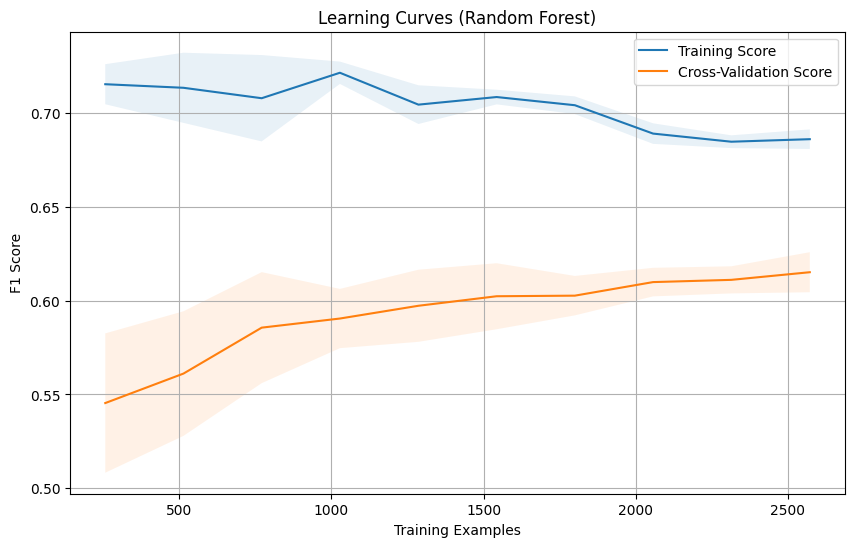

Adjusted Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       587
           1       0.27      1.00      0.43       217

    accuracy                           0.27       804
   macro avg       0.13      0.50      0.21       804
weighted avg       0.07      0.27      0.11       804



c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

In [70]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import (
    classification_report,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve
)

# Hyperparameter tuning
param_grid = {'n_estimators': [100], 'max_depth': [5, 8, 10],
              'min_samples_split': [10, 15], 'min_samples_leaf': [2, 5]}
rf = RandomForestClassifier(random_state=42, class_weight='balanced')  
grid_rf = GridSearchCV(rf, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

# Best model
best_rf = grid_rf.best_estimator_
y_pred_train = best_rf.predict(X_train_scaled)
y_pred_test = best_rf.predict(X_test_scaled)

# Evaluate on training and test 
print("Best Parameters:", grid_rf.best_params_)

print("\nTraining Set:")
print("Classification Report (Training):\n", classification_report(y_train , y_pred_train))
print("F1 (Training):", f1_score(y_train, y_pred_train))
print("Accuracy (Training):", accuracy_score(y_train, y_pred_train))

print("\nTest Set:")
print("Classification Report (Test):\n", classification_report(y_test, y_pred_test))
print("F1 (Test):", f1_score(y_test, y_pred_test))
print("Precision (Test):", precision_score(y_test, y_pred_test))
print("Recall (Test):", recall_score(y_test, y_pred_test))
print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))


y_probs_rf = best_rf.predict_proba(X_test_scaled)
auc_class_1 = roc_auc_score(y_test, y_probs_rf[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_rf[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")


train_sizes, train_scores, val_scores = learning_curve(best_rf, X_train_scaled, y_train, cv=5, n_jobs=-1, 
                                                       train_sizes=np.linspace(0.1, 1.0, 10), scoring='f1')

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, val_mean, label='Cross-Validation Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1)
plt.xlabel('Training Examples')
plt.ylabel('F1 Score')
plt.title('Learning Curves (Random Forest)')
plt.legend(loc='best')
plt.grid()
plt.show()

y_probs = y_probs_rf[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)
thresh = thresholds[np.argmax(recall > 0.7)]
y_pred_adjusted = (y_probs >= thresh).astype(int)

print("Adjusted Classification Report:\n", classification_report(y_test, y_pred_adjusted))


c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:57:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

Training Set:
Classification Report (Training):
               precision    recall  f1-score   support

           0       0.88      0.97      0.93      2340
           1       0.90      0.66      0.76       876

    accuracy                           0.89      3216
   macro avg       0.89      0.82      0.84      3216
weighted avg       0.89      0.89      0.88      3216

F1 (Training): 0.761528326745718
Accuracy (Training): 0.8874378109452736

Test Set:
Classification Report (Test):
               precision    recall  f1-score   support

           0       0.83      0.93      0.88       587
           1       0.72      0.48      0.58       217

    accuracy                           0.81       804
   macro avg       0.78      0.71      0.73       804
weighted avg       0.80      0.81      0.80       804

F1 (Test): 0.5761772853185596
Precision (Test): 0.7222222222222222
Recall (Test): 0.4792626728110599
Acc

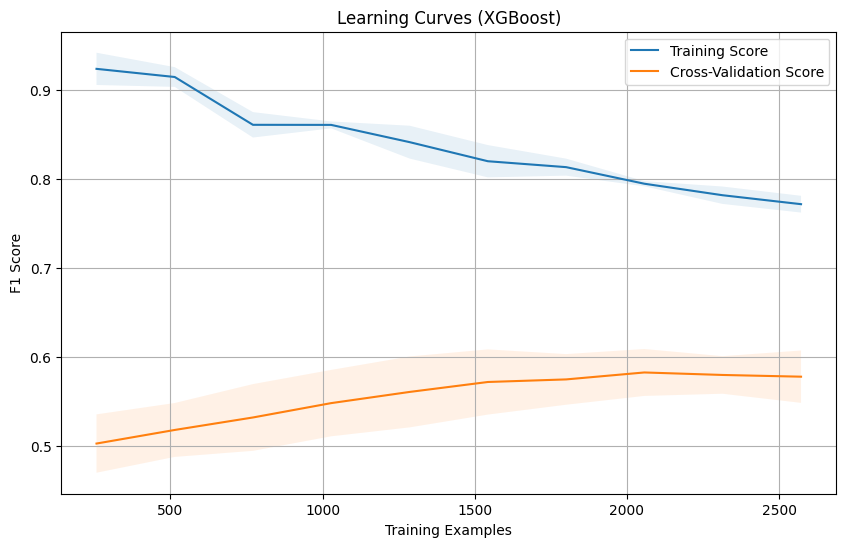

Adjusted Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       587
           1       0.27      1.00      0.43       217

    accuracy                           0.27       804
   macro avg       0.13      0.50      0.21       804
weighted avg       0.07      0.27      0.11       804



c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\BCSbgayet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

In [73]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.metrics import (
    classification_report,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt
import numpy as np

# Hyperparameter tuning
param_grid = {
    'learning_rate': [0.1],
    'max_depth': [5, 7, 10],
    'n_estimators': [100, 200]
}
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

grid_xgb = GridSearchCV(xgb, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train)

# Best model
best_xgb = grid_xgb.best_estimator_
y_pred_train = best_xgb.predict(X_train_scaled)
y_pred_test = best_xgb.predict(X_test_scaled)

# Evaluation
print("Best Parameters:", grid_xgb.best_params_)

print("\nTraining Set:")
print("Classification Report (Training):\n", classification_report(y_train, y_pred_train))
print("F1 (Training):", f1_score(y_train, y_pred_train))
print("Accuracy (Training):", accuracy_score(y_train, y_pred_train))

print("\nTest Set:")
print("Classification Report (Test):\n", classification_report(y_test, y_pred_test))
print("F1 (Test):", f1_score(y_test, y_pred_test))
print("Precision (Test):", precision_score(y_test, y_pred_test))
print("Recall (Test):", recall_score(y_test, y_pred_test))
print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))

y_probs_xgb = best_xgb.predict_proba(X_test_scaled)
auc_class_1 = roc_auc_score(y_test, y_probs_xgb[:, 1])
auc_class_0 = roc_auc_score(1 - y_test, y_probs_xgb[:, 0])

print(f"ROC AUC for class 0: {auc_class_0:.4f}")
print(f"ROC AUC for class 1: {auc_class_1:.4f}")

train_sizes, train_scores, val_scores = learning_curve(
    best_xgb, X_train_scaled, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='f1'
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, val_mean, label='Cross-Validation Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1)
plt.xlabel('Training Examples')
plt.ylabel('F1 Score')
plt.title('Learning Curves (XGBoost)')
plt.legend(loc='best')
plt.grid()
plt.show()

y_probs = y_probs_xgb[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)
thresh = thresholds[np.argmax(recall > 0.7)]
y_pred_adjusted = (y_probs >= thresh).astype(int)

print("Adjusted Classification Report:\n", classification_report(y_test, y_pred_adjusted))


## **Section D:** Interpretation & Recommendations

### *1. Feature Importance*

C:\Users\BCSbgayet\AppData\Local\Temp\ipykernel_11916\3128013624.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='viridis')


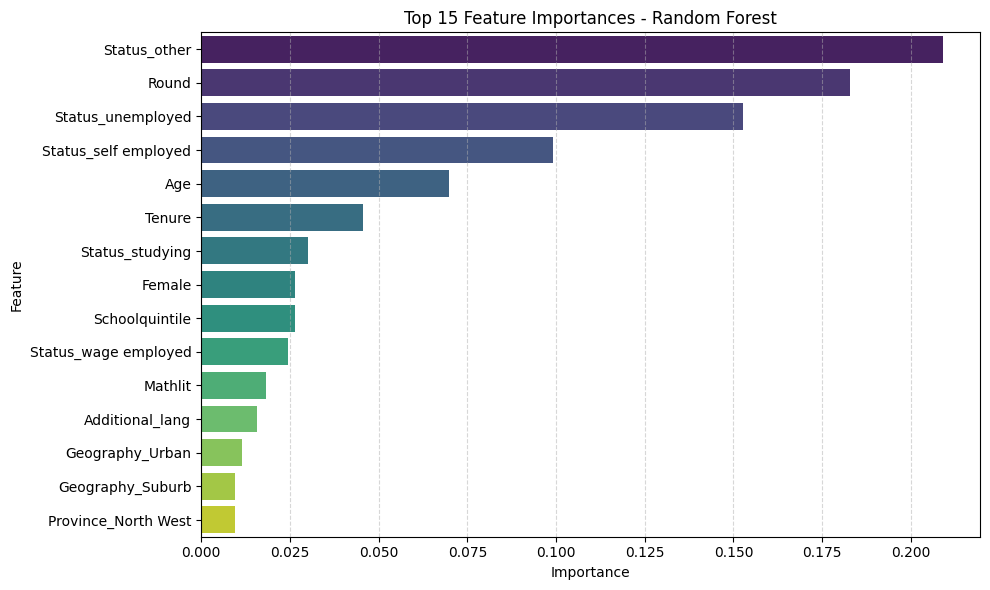

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importances = best_rf.feature_importances_

feature_names = X_train.columns

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

 
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()



##### The Random Forest model provides a clear view of which features are most influential in predicting employment status one year after graduation.  Below is the list of features ranked by importance (starting from the most impactful):                                                                     **1/Status_other** – students who reported "other" as their status (e.g., inactive or undefined) are strongly associated with unemployment.                    **2/Round** – the survey round (or time point) significantly affects employment probability, possibly due to changes in the job market or graduation timing.    **3/Status_unemployed** – unsurprisingly, those previously unemployed are at greater risk of remaining unemployed.                                             **4/Status_selfemployed** – indicates a transition path; this feature helps separate alternative employment outcomes.                                          **5/Age** – older individuals may face more challenges in entering the job market.                                                                             **6/Tenure** – prior job experience still plays a role but is slightly less influential than status variables.                                                  **7/Status_studying** – current students are somewhat less likely to be employed yet.                                                                          **8/Female** – gender has a mild but measurable impact on employment, potentially due to structural inequalities or labor market segmentation.       *Interpretation:*                                                                                                                                    Features related to current or past status (such as "other", "unemployed", or "studying") are the strongest predictors of employment outcomes.             Structural features like age, experience (tenure), and gender come next, reflecting known socio-economic barriers to employment.

### *2. Business Insight*

#### The insights gained from the feature importance analysis can guide educational institutions, policy makers, and employment support programs to design targeted interventions that improve graduate employability.



####  **A. Support "Inactive" Youth (Status = Other)*
##### Insight: The most important feature was Status_other. Students who were neither studying, nor employed, nor actively seeking employment (i.e., "other") had the highest risk of long-term unemployment.

#### **Recommendation:**
##### Implement early detection systems to flag inactive students before graduation.
##### Offer personalized coaching, motivation workshops, and career guidance during the final academic year.

#### **B. Improve Transition-to-Work Programs*
##### Insight: Features like Status_unemployed, Status_selfemployed, and Status_studying are strong predictors.

#### **Recommendation:**
##### Introduce job search support programs for final-year students and recent graduates.
##### Facilitate access to entrepreneurship training and incubators for self-employed youth.
##### Create bridging programs for students about to finish school (internships, real-world simulations).

#### **C. Monitor Academic Timing (Round)*
##### Insight: The Round variable is highly predictive — employment outcomes shift depending on graduation year or time of survey.

#### **Recommendation:**
##### Track and analyze job market trends aligned with academic calendars.
##### Align graduate support services with the most relevant employment cycles (e.g., graduate recruitment seasons).

#### **D. Address Age and Gender Disparities*
##### Insight: Age and Female are influential features, suggesting possible barriers to employment for older graduates and women.

#### **Recommendation:**
##### Promote inclusive hiring practices and gender equity policies in employer outreach.
##### Design programs tailored to non-traditional graduates (e.g., those returning to education later in life).

